In [2]:
import uproot
import pandas
import numpy as np
import os

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt

uproot.__version__

'5.0.8'

<!-- <img src="../data/morozov_2010_spectrum.png" alt="photo_morozov_2010_spectrum" width="300"> -->
<!-- <img src="../data/morozov_UV_yields.png" alt="photo_morozov_UV_yields" width="300"> -->

<div style="display:flex">
  <img src="../data/morozov_2010_spectrum.png" alt="photo_morozov_2010_spectrum" width="500">
  <img src="../data/morozov_UV_yields.png" alt="photo_morozov_UV_yields" width="500">
</div>


In [3]:
## loading the data ##
# Define the folder path
opticsPath = "../g4PDEsim/dataOptics/"
scintPath = "../g4PDEsim/data/"
dataPath = "../data/"

In [53]:
## loading all scintillation data ##

if os.path.exists(file_path := os.path.join(scintPath, "cf4Scint_1bar_all.txt")):
  print(file_path, "exists")

## all morozov data
xMoroz1Bar, yMoroz1Bar = np.loadtxt(os.path.join(scintPath, "cf4Scint_1bar_all.txt"), unpack=True, skiprows=1)
xt, yt = np.loadtxt(os.path.join(scintPath, "cf4Scint_5bar_Vis.txt"), unpack=True, skiprows=1)
xt2, yt2 = np.loadtxt(os.path.join(scintPath, "cf4Scint_5bar_UV.txt"), unpack=True, skiprows=1)
xMoroz5Bar = np.concatenate((xt2, xt))
yMoroz5Bar = np.concatenate((yt2, yt))

##-- listing UV yields and max values from spectrum --##
# uvYields, 0.5 bar, from Morozov
lyUV_moroz05bar = 2280. # from table. stops at 200nm
lyUV_moroz1bar = (2150+1980)/2. # from table. stops at 200nm

# uv 5 bar yields, from Morozov
ly1 = [707, 858-707] # two measurements, weighted average by errors
ly2 = [665, 777-665] # values taken from webPlotDigitizer (tables in data folder)
etot = ly1[1] + ly2[1]
lyUV_moroz5bar = (ly1[0]*(ly1[1]/etot)  + ly2[0]*ly2[1]/etot) # do weighted average
# print(lyUV_moroz5bar)

# max heights
vis_max5bar = 33.5 # ph/MeV nm, from inspecting the graph
uv_max5bar = 7. # ph/MeV nm, from inspecting the graph
uv_max1bar = 23.5 # ph/MeV nm, from inspecting the graph

# scaling Morozov data (which is in AU)
yMoroz1Bar *= (uv_max1bar/max(yMoroz1Bar))
yMoroz5Bar *= (vis_max5bar/max(yMoroz5Bar))

##-- deep UV component --##
xGernCf4, yGernCf4 = np.loadtxt(os.path.join(dataPath, "gernhauser_cf4_05bar_spikes.csv"), delimiter=',', skiprows=1, unpack=True)
xGernCf4Smooth, yGernCf4Smooth = np.loadtxt(os.path.join(dataPath, "gernhauser_cf4_05bar.csv"), delimiter=',', skiprows=1, unpack=True)
xGernCf4 = xGernCf4Smooth # use non-spikey data (spikes are contamination)
yGernCf4 = yGernCf4Smooth

gern_sort = np.argsort(xGernCf4)
xGernCf4_sorted = xGernCf4[gern_sort]
yGernCf4_sorted = yGernCf4[gern_sort]
# yGernCf4_sorted_smoother = scipy.ndimage.uniform_filter1d(yGernCf4_sorted, size= 10) # smoothing. not needed

## now scale data (which is in AU) to ly/MeV using max values from above
# morozov defines UV as below 500nm
# scaling Gern to match Moroz from 200nm to 320nm (end of Gern)

# first scale Moroz 1 bar data to the 0.5 bar LY
intensity1 = scipy.integrate.simps(yMoroz1Bar[np.where(xMoroz1Bar<500)], xMoroz1Bar[np.where(xMoroz1Bar<500)])
yMoroz05Bar = yMoroz1Bar * (lyUV_moroz05bar/intensity1)
print((lyUV_moroz05bar/intensity1))
print(lyUV_moroz05bar/lyUV_moroz1bar) # should be close to eachother (10% dif from 1bar to 0.5bar given in paper)

xMoroz05Bar = xMoroz1Bar

# now scale Gern in that region to match Moroz 0.5 bar
# they overlap between min(xMoroz05Bar) ~220nm, and max(xGernCf4_sorted) ~320nm
# mask = (x >= min(xMoroz05Bar)) & (x <= max(xGernCf4_sorted))
# x_selected = x[mask]
# y_selected = y[mask]

intensityMoroz_restrictedArea = scipy.integrate.simps(yMoroz05Bar[np.where( xMoroz05Bar < max(xGernCf4_sorted))], xMoroz05Bar[np.where(xMoroz05Bar < max(xGernCf4_sorted))])
intensityGern_restrictedArea = scipy.integrate.simps(yGernCf4_sorted[np.where( xGernCf4_sorted > min(xMoroz05Bar))], xGernCf4_sorted[np.where( xGernCf4_sorted > min(xMoroz05Bar))])

scaledGernY = yGernCf4_sorted * (intensityMoroz_restrictedArea/intensityGern_restrictedArea)


../g4PDEsim/data/cf4Scint_1bar_all.txt exists
1.1015865674249306
1.1041162227602905


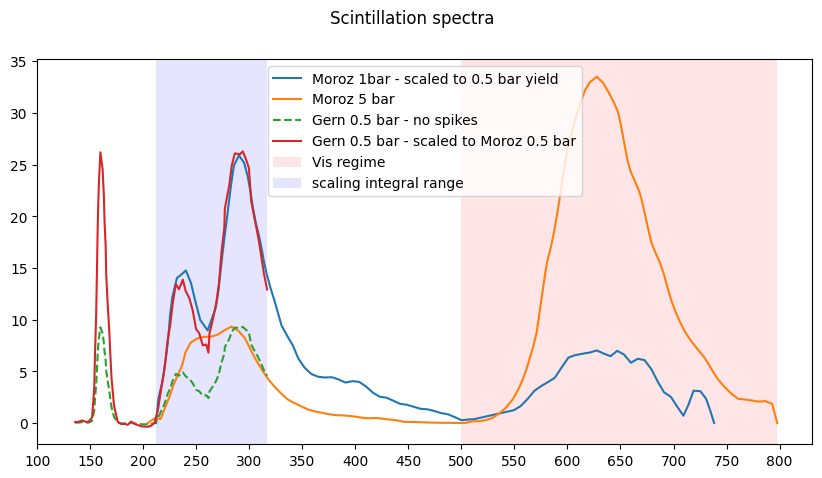

In [75]:
fig, (ax1) = plt.subplots(1, 1, figsize=(10, 5))
fig.suptitle("Scintillation spectra")  # Add the title at the top of the figure

ax1.plot(xMoroz05Bar, yMoroz05Bar, label="Moroz 1bar - scaled to 0.5 bar yield")
ax1.plot(xMoroz5Bar, yMoroz5Bar, label="Moroz 5 bar")

ax1.plot(xGernCf4_sorted, yGernCf4_sorted, linestyle="--", label="Gern 0.5 bar - no spikes")

ax1.plot(xGernCf4_sorted, scaledGernY, linestyle="-", label="Gern 0.5 bar - scaled to Moroz 0.5 bar")

ax1.axvspan(500, max(xMoroz5Bar), facecolor='red', alpha=0.1, label = "Vis regime")

ax1.axvspan(min(xMoroz05Bar), max(xGernCf4_sorted), facecolor='blue', alpha=0.1, label = "scaling integral range")

ax1.legend(loc="upper center")  # Place the legend in the top right corner

# Add tick marks starting at 100nm and going up every 50
ax1.set_xticks(np.arange(100, 850, 50))

plt.show()

In [6]:
## Silicon n and k
siX, siY = np.loadtxt(os.path.join(opticsPath, "siliconRINDEX_100nm_Pierce.txt"), skiprows=1, unpack = True)
siX *= 1000
sikX, sikY = np.loadtxt(os.path.join(opticsPath, "siliconKINDEX_100nm_Pierce.txt"), skiprows=1, unpack = True)
sikX *= 1000

## SiO2 n and k
sioX, sioN, sioK = np.loadtxt(os.path.join(opticsPath, "sio2-fusedQuartz_uv_web.txt"), skiprows=1, unpack = True)
sioX2, sioN2, sioK2 = np.loadtxt(os.path.join(opticsPath, "sio2-fusedQuartz_vuv_web.txt"), skiprows=1, unpack = True)
sioX_ri, sioN_ri = np.loadtxt(os.path.join(opticsPath, "sio2_refInfo_malitson.txt"), skiprows=1, unpack = True)
sioX_ri *= 1000

g4sio2X, g4sio2N = np.loadtxt(os.path.join(opticsPath, "g4_sio2_rindex.txt"), skiprows=1, unpack = True)
g4sio2X = 1240/(g4sio2X*1e6)

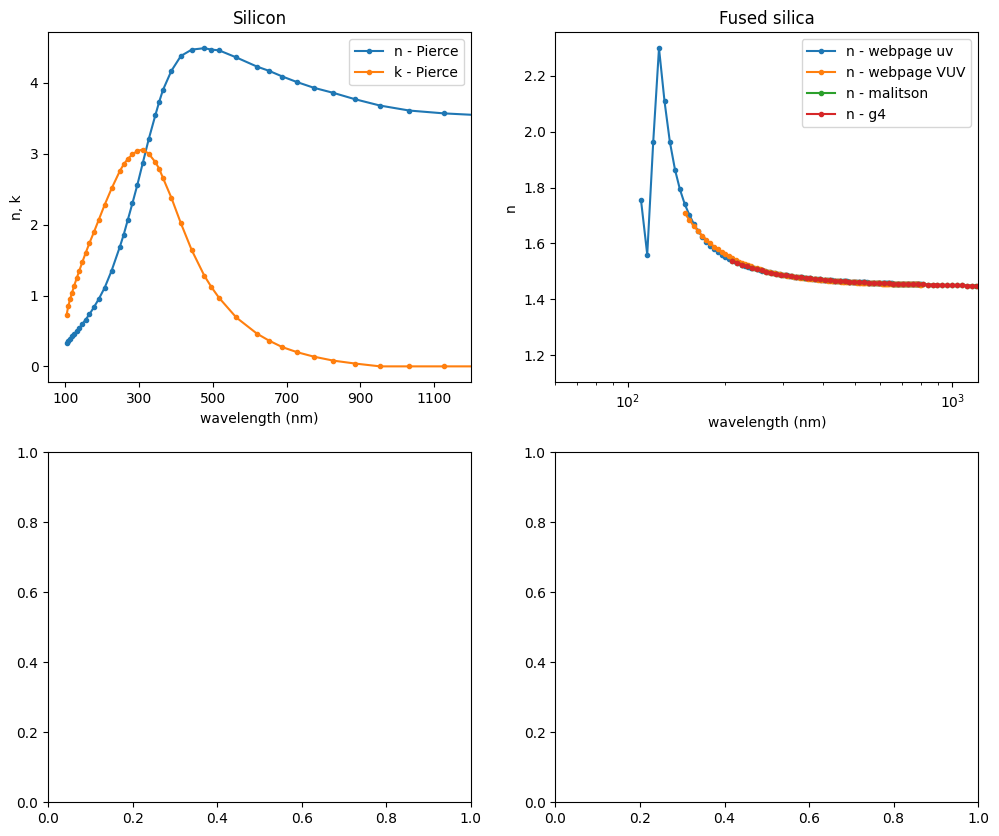

In [94]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
minWl = 100
maxWl = 1200

### silicon ###
ax[0, 0].set_title("Silicon")
ax[0, 0].plot(siX, siY, marker=".", label="n - Pierce")
ax[0, 0].plot(sikX, sikY, marker=".", label="k - Pierce")
# ax[0, 0].plot(sikX, siY+sikY, marker=".", label="Si n+k")

ax[0, 0].set_xlabel("wavelength (nm)")
ax[0, 0].set_ylabel("n, k")
ax[0, 0].legend()
ax[0, 0].set_xticks(np.arange(100, maxWl, 200))
ax[0, 0].set_xlim(min(siX)-50, maxWl)

### fused silica ###
ax[0, 1].set_title("Fused silica")

ax[0, 1].semilogx(sioX, sioN, marker=".", label="n - webpage uv")
ax[0, 1].semilogx(sioX2, sioN2, marker=".", label="n - webpage VUV")
ax[0, 1].semilogx(sioX_ri, sioN_ri, marker=".", label="n - malitson")
ax[0, 1].semilogx(g4sio2X, g4sio2N, marker=".", label="n - g4")

# ax[0, 1].semilogx(sioX, sioK, marker=".", label="k - webpage uv")
# ax[0, 1].semilogx(sioX2, sioK2, marker=".", label="k - webpage VUV")


# ax[0, 1].tick_params(axis='y', labelcolor='blue')
ax[0, 1].set_xlabel("wavelength (nm)")
ax[0, 1].set_ylabel("n")
ax[0, 1].set_xlim(min(sioX)-50, maxWl)

# Create a twin y-axis on the left side
# ax2 = ax[0, 1].twinx()
# ax2.set_ylabel("k - Malitson", color='red')
# ax2.semilogy(sioX, sioK, marker=".", label="k - webpage", color='red')
# ax2.tick_params(axis='y', labelcolor='red')

# Show the legend for both y-axes
ax[0, 1].legend(loc='upper right')
# ax2.legend(loc='upper right')
ax[0, 1].legend()

# ax[0, 1].set_xticks(np.arange(100, 1200, 200))
# ax[0, 1].set_xlim(min(siX)-50, 1200)

# Show the plot
plt.show()
